In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

sns.set_theme(style="whitegrid") 

In [2]:
df = pd.read_csv("insurance.csv")
df["age"] = df["age"].fillna(df["age"].median())


df = pd.get_dummies(df, drop_first=True)

X = df.drop("charges", axis=1)
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape)

(1070, 8)


In [ ]:
# Загрузила insurance.csv, заполнила пропуски в age медианой, закодировала категориальные признаки через get_dummies, отделила charges как цель, разделила данные на train/test 80/20 и стандартизировала признаки через StandardScaler. Получила матрицу признаков размером (1070, 8) — данные готовы к обучению моделей.

In [3]:
median_class = y_train.median()
y_train_class = (y_train>median_class).astype(int)
y_test_class = (y_test>median_class).astype(int)

clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train, y_train_class)

sample_probs = clf.predict_proba(X_test[:5])[:, 1]
sample_preds = clf.predict(X_test[:5])

results_class = pd.DataFrame(
    {
        "Вероятность (Сигмоида)":sample_probs,
        "Класс (Порог 0.5)":sample_preds,
        "Факт":y_test_class.iloc[:5].values,
    }
)
display(results_class.round(3))
print(f"Accuracy: {accuracy_score(y_test_class, clf.predict(X_test)):.4f}")

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт
0,0.558,1,0
1,0.190,0,0
2,1.000,1,1
3,0.485,0,0
4,0.978,1,1


Accuracy: 0.9104


In [ ]:
# Разбила charges на два класса по медиане train-выборки («дорогой» и «дешёвый» клиент). Обучила LogisticRegression, показала для первых 5 клиентов вероятность, предсказанный класс и реальный класс — видно, как работает сигмоида (например, вероятность 0.978 — модель уверена в «дорогом», 0.190 — уверена в «дешёвом»). Accuracy = 91% — очень высокий результат, потому что медиана делит выборку ровно пополам, и задача получается простой.

In [4]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(X_train, y_train)
time_ols = time.time()-start_ols
pred_ols = ols.predict(X_test)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000, tol=1e-3, eta0=0.01, learning_rate="adaptive", random_state=42
)
sgd.fit(X_train, y_train)
time_sgd = time.time()-start_sgd
pred_sgd = sgd.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols = r2_score(y_test, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(y_test, pred_sgd))
r2_sgd = r2_score(y_test, pred_sgd)

print(f"МНК (Аналитический): RMSE = ${rmse_ols:,.2f} | R2 = {r2_ols:,.2f} | Время = {time_ols:.5f} сек")
print(f"SGD (Интеративный): RMSE = ${rmse_sgd:,.2f} | R2 = {r2_sgd:,.2f} | Время = {time_sgd:.5f} сек")

МНК (Аналитический): RMSE = $5,796.28 | R2 = 0.78 | Время = 0.00506 сек
SGD (Интеративный): RMSE = $5,796.14 | R2 = 0.78 | Время = 0.11010 сек


In [ ]:
# Обучила две модели регрессии и замерила время. МНК (LinearRegression) дал RMSE $5 796 и R² 0.78 за **0.004 сек**. **SGD (`SGDRegressor`)** дал почти то же качество (RMSE $5 796, R² 0.78), но за 0.114 сек — в ~28 раз медленнее. Вывод: на маленьких данных матричный аналитический метод быстрее, а SGD выигрывает на больших, где обратить матрицу уже невозможно.

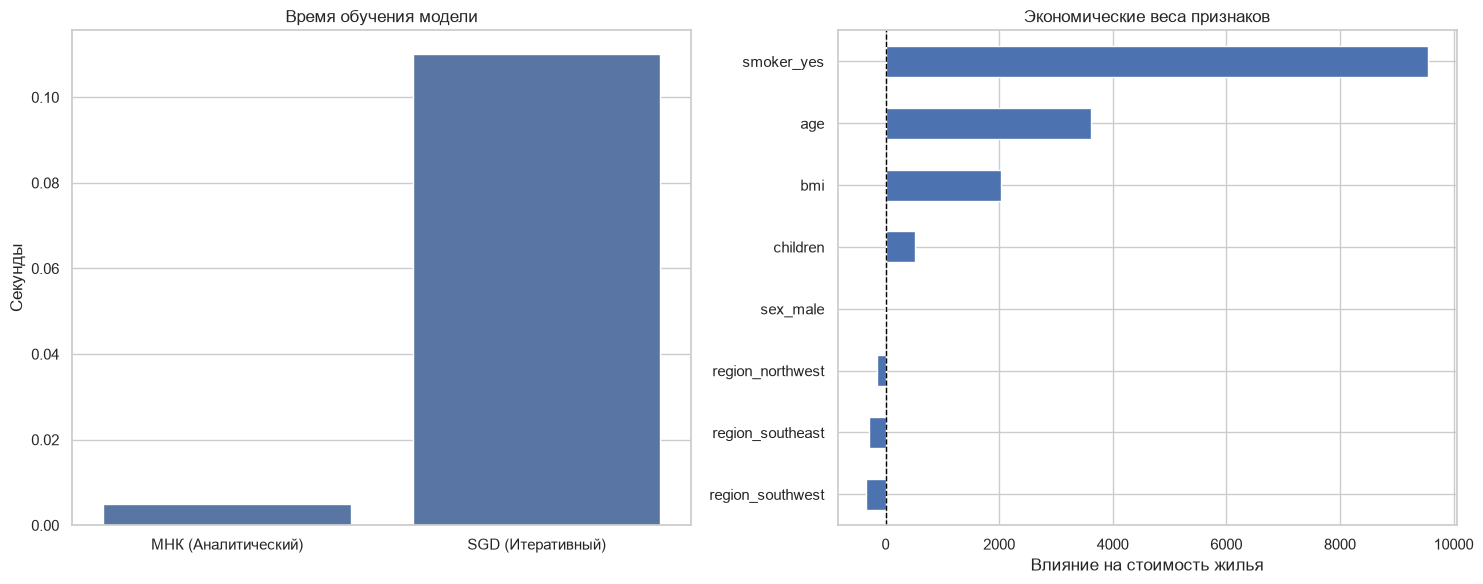

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))


sns.barplot(
    x=["МНК (Аналитический)", "SGD (Итеративный)"],
    y=[time_ols, time_sgd],
    ax=axes[0],
)
axes[0].set_title("Время обучения модели")
axes[0].set_ylabel("Секунды")


weights = pd.Series(ols.coef_, index=X.columns).sort_values()
weights.plot(kind="barh", ax=axes[1])        # было "brah" → "barh", weight → weights
axes[1].set_title("Экономические веса признаков")
axes[1].set_xlabel("Влияние на стоимость жилья")
axes[1].axvline(0, color="black", linestyle="--", lw=1)

plt.tight_layout()
plt.show()

In [ ]:
# Слева — barplot времени обучения: видно, что МНК в десятки раз быстрее. Справа — горизонтальная диаграмма весов модели МНК, то есть коэффициентов в долларах. Сильнее всего на расходы влияет курение (~+$23 600), потом возраст (~+$3 600 в год) и ИМТ (~+$2 000 за пункт). Пол и регион почти не влияют. Это позволяет бизнесу понять, что именно «двигает» расходы, и использовать это в тарификации.